# Sign Transformer + CTC 輔助損失

跟 `sign_transformer_copy.ipynb` 的差別 (其他設定都一樣，方便比較)：

| 改動 | 目的 |
|---|---|
| **encoder 加一個 CTC 輸出層**，總損失 = (1 − `CTC_WEIGHT`) × 翻譯損失 + `CTC_WEIGHT` × CTC 損失 | 逼 encoder 自己從手勢讀出字，不能全部丟給 decoder 去猜 |
| **decoder 從 3 層減到 2 層** (`DEC_LAYERS`) | 降低 decoder 自己背句子的能力 |
| **decoder 輸入隨機遮字** (`WORD_DROPOUT`)：訓練時把一部分「前面的字」換成 `<unk>` | 讓 decoder 不能只靠前文猜下一個字，必須去看手勢 |
| 預測時多輸出一份 **CTC 直接解碼**的結果 | 單獨檢查 encoder 學到多少 |

資料沿用原本 notebook 已經建好的 `data/` (同樣的 train / val / test、字典、norm)，所以結果可以直接跟之前比。

**判斷有沒有效**：
1. 診斷實驗的「有手勢 vs 沒有手勢」val loss 差距，要比之前的 0.05～0.07 明顯變大
2. 評估表的「新句 CER」、「新句精確率」要明顯贏過之前的 1.03 / 0.09

In [1]:
import csv
import json
import math
import os
import random
import re
import unicodedata
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

warnings.filterwarnings("ignore")
# os.chdir(r"C:\你的專案資料夾\Data Training")

# ================================================================ 實驗設定
SEG_TAG = ""               # 用哪一種切法的資料："" = 原本，"_m0.5" = 寬鬆切法
RUN_TAG = "_ctc"           # 這次實驗的名稱，checkpoints / predictions 會加上這個後綴

# ================================================================ 路徑設定
LABEL_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03labels" + SEG_TAG)
SEG_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03segments" + SEG_TAG)
DATA_DIR = Path(r"data" + SEG_TAG)                   # 跟原本的 notebook 共用
CKPT_DIR = Path(r"checkpoints" + SEG_TAG + RUN_TAG)
PRED_DIR = Path(r"predictions" + SEG_TAG + RUN_TAG)              # decoder (翻譯) 的預測
PRED_DIR_CTC = Path(r"predictions" + SEG_TAG + RUN_TAG + "_enc")  # CTC 直接解碼的預測

# ================================================================ 資料集切分 (DATA_DIR 已經有資料時不會重建)
SPLIT = (0.8, 0.1, 0.1)
SEED = 42
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]
FLAG_DIMS = [126, 127, 155]
MIN_FREQ = 2

# ================================================================ 資料設定
FRAME_STRIDE = 2
MAX_FRAMES = 300
MAX_TEXT_LEN = 64
SPEED_RANGE = (0.8, 1.2)
NOISE_STD = 0.05

# ================================================================ 模型設定
D_MODEL = 256
N_HEADS = 4
ENC_LAYERS = 4
DEC_LAYERS = 2             # 原本 3
FF_DIM = 1024
DROPOUT = 0.3

# ================================================================ 新增：CTC 與 decoder 遮字
CTC_WEIGHT = 0.5           # 總損失裡 CTC 佔的比例 (0 = 跟原本一樣，只有翻譯損失)
WORD_DROPOUT = 0.25        # 訓練時 decoder 輸入有多少比例的字換成 <unk>

# ================================================================ 訓練設定
BATCH_SIZE = 32
EPOCHS = 150
LR = 3e-4
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 5
LABEL_SMOOTHING = 0.1
PATIENCE = 10              # val 翻譯損失連續幾個 epoch 沒進步就停止
VAL_CER_EVERY = 5

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
PAD, BOS, EOS, UNK = 0, 1, 2, 3
BLANK = PAD                # CTC 的空白符號借用 <pad> (它不會出現在答案裡)
print("device:", DEVICE)

device: cuda


## DATASET
`DATA_DIR` 裡已經有 `train.csv`、`vocab.json`、`norm.npz` 就直接沿用，不重新切分。

In [2]:
if all((DATA_DIR / name).exists() for name in ("train.csv", "val.csv", "test.csv", "vocab.json", "norm.npz")):
    print(f"沿用 {DATA_DIR} 裡現有的資料切分、字典與 norm")
else:
    print(f"{DATA_DIR} 沒有完整資料，重新建立")
    groups = {}
    for txt in sorted(LABEL_DIR.glob("*/*/*.txt")):
        group = txt.parent.relative_to(LABEL_DIR)
        for line in txt.read_text(encoding="utf-8").splitlines():
            name, _, text = line.partition(": ")
            if text.strip():
                groups.setdefault(group.as_posix(), []).append(((group / f"{name}.npy").as_posix(), text.strip()))

    keys = sorted(groups)
    random.Random(SEED).shuffle(keys)
    n_train, n_val = round(len(keys) * SPLIT[0]), round(len(keys) * SPLIT[1])
    splits = {"train": keys[:n_train], "val": keys[n_train:n_train + n_val], "test": keys[n_train + n_val:]}

    DATA_DIR.mkdir(parents=True, exist_ok=True)
    rows = {}
    for split, split_keys in splits.items():
        rows[split] = [row for key in sorted(split_keys) for row in groups[key]]
        with (DATA_DIR / f"{split}.csv").open("w", newline="", encoding="utf-8-sig") as f:
            writer = csv.writer(f)
            writer.writerow(("path", "text"))
            writer.writerows(rows[split])

    freq = Counter(c for _, text in rows["train"] for c in text)
    chars = sorted(c for c, n in freq.items() if n >= MIN_FREQ)
    (DATA_DIR / "vocab.json").write_text(json.dumps(SPECIALS + chars, ensure_ascii=False), encoding="utf-8")

    total, total_sq, count = np.zeros(156), np.zeros(156), 0
    for path, _ in tqdm(rows["train"], desc="norm"):
        arr = np.load(SEG_DIR / path).astype(np.float64)
        total += arr.sum(0)
        total_sq += (arr ** 2).sum(0)
        count += len(arr)
    mean = total / count
    std = np.sqrt(np.maximum(total_sq / count - mean ** 2, 0)) + 1e-6
    mean[FLAG_DIMS], std[FLAG_DIMS] = 0.0, 1.0
    np.savez(DATA_DIR / "norm.npz", mean=mean.astype(np.float32), std=std.astype(np.float32))

for split in ("train", "val", "test"):
    with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
        print(f"{split}: {sum(1 for _ in csv.DictReader(f))} 句")
print("字元數:", len(json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))) - len(SPECIALS))

沿用 data 裡現有的資料切分、字典與 norm
train: 17901 句
val: 2234 句
test: 2265 句
字元數: 2662


In [3]:
def load_vocab():
    return json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))


class SignDataset(Dataset):
    def __init__(self, split, vocab, train=False):
        with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
            self.rows = [(row["path"], row["text"]) for row in csv.DictReader(f)]
        self.stoi = {c: i for i, c in enumerate(vocab)}
        norm = np.load(DATA_DIR / "norm.npz")
        self.mean, self.std = norm["mean"], norm["std"]
        self.train = train
        self.cache = [
            np.ascontiguousarray(((np.load(SEG_DIR / path).astype(np.float32) - self.mean) / self.std)[::FRAME_STRIDE])
            for path, _ in tqdm(self.rows, desc=f"load {split}")
        ]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        text = self.rows[i][1]
        x = self.cache[i]
        if self.train:
            n = max(1, round(len(x) * random.uniform(*SPEED_RANGE)))
            x = x[np.linspace(0, len(x) - 1, n).round().astype(int)]
            x = x + np.random.normal(0, NOISE_STD, x.shape).astype(np.float32)
        x = x[:MAX_FRAMES]
        ids = [BOS] + [self.stoi.get(c, UNK) for c in text[:MAX_TEXT_LEN - 2]] + [EOS]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.tensor(ids)


def collate(batch):
    xs, ys = zip(*batch)
    src = nn.utils.rnn.pad_sequence(xs, batch_first=True)
    lengths = torch.tensor([len(x) for x in xs])
    src_mask = torch.arange(src.size(1))[None, :] >= lengths[:, None]     # True = padding
    tgt = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=PAD)
    return src, src_mask, tgt

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=2000):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:x.size(1)]


class SignTransformerCTC(nn.Module):
    def __init__(self, vocab_size, feat_dim=156):
        super().__init__()
        self.src_proj = nn.Sequential(
            nn.Linear(feat_dim, D_MODEL), nn.LayerNorm(D_MODEL), nn.GELU(),
            nn.Dropout(DROPOUT), nn.Linear(D_MODEL, D_MODEL),
        )
        self.tgt_emb = nn.Embedding(vocab_size, D_MODEL, padding_idx=PAD)
        self.pos = PositionalEncoding(D_MODEL)
        self.transformer = nn.Transformer(
            D_MODEL, N_HEADS, ENC_LAYERS, DEC_LAYERS, FF_DIM, DROPOUT,
            batch_first=True, norm_first=True,
        )
        self.out = nn.Linear(D_MODEL, vocab_size)
        # 新增：encoder 每個 frame 直接預測字 (含 blank)
        self.ctc_norm = nn.LayerNorm(D_MODEL)
        self.ctc_out = nn.Linear(D_MODEL, vocab_size)

    def encode(self, src, src_mask):
        return self.transformer.encoder(self.pos(self.src_proj(src)), src_key_padding_mask=src_mask)

    def ctc_logits(self, memory):
        return self.ctc_out(self.ctc_norm(memory))

    def decode(self, tgt, memory, src_mask):
        L = tgt.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=tgt.device), 1)
        h = self.transformer.decoder(
            self.pos(self.tgt_emb(tgt) * math.sqrt(D_MODEL)), memory,
            tgt_mask=causal, tgt_key_padding_mask=tgt == PAD, memory_key_padding_mask=src_mask,
        )
        return self.out(h)

    def forward(self, src, src_mask, tgt_in):
        """回傳 (decoder logits, CTC logits)。訓練時 decoder 輸入會隨機遮字。"""
        memory = self.encode(src, src_mask)
        if self.training and WORD_DROPOUT > 0:
            drop = (torch.rand(tgt_in.shape, device=tgt_in.device) < WORD_DROPOUT) & (tgt_in > UNK)
            tgt_in = tgt_in.masked_fill(drop, UNK)          # <bos>、<pad> 不遮
        return self.decode(tgt_in, memory, src_mask), self.ctc_logits(memory)

In [5]:
def compute_loss(model, src, src_mask, tgt, ce_criterion, ctc_criterion):
    """回傳 (總損失, 翻譯損失, CTC 損失)。"""
    logits, ctc_logits = model(src, src_mask, tgt[:, :-1])
    ce = ce_criterion(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))

    # CTC 的答案 = 去掉 <bos> / <eos> / <pad> 的字
    gold = tgt[:, 1:]
    keep = (gold != PAD) & (gold != EOS)
    log_probs = ctc_logits.float().log_softmax(-1).transpose(0, 1)       # (T, N, C)
    input_lengths = (~src_mask).sum(1)
    ctc = ctc_criterion(log_probs, gold[keep], input_lengths, keep.sum(1))
    return (1 - CTC_WEIGHT) * ce + CTC_WEIGHT * ctc, ce, ctc


def run_epoch(model, loader, ce_criterion, ctc_criterion, optimizer=None, scheduler=None, scaler=None,
              zero_input=False):
    """回傳 (平均翻譯損失, 平均 CTC 損失)，翻譯損失以字數加權。"""
    train = optimizer is not None
    model.train(train)
    ce_total = ctc_total = 0.0
    count = n_batch = 0
    for src, src_mask, tgt in loader:
        if zero_input:
            src = torch.zeros_like(src)
        src, src_mask, tgt = src.to(DEVICE), src_mask.to(DEVICE), tgt.to(DEVICE)
        with torch.set_grad_enabled(train), torch.autocast(DEVICE, enabled=USE_AMP):
            loss, ce, ctc = compute_loss(model, src, src_mask, tgt, ce_criterion, ctc_criterion)
        if train:
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
        n = (tgt[:, 1:] != PAD).sum().item()
        ce_total += ce.item() * n
        count += n
        ctc_total += ctc.item()
        n_batch += 1
    return ce_total / count, ctc_total / max(1, n_batch)

In [6]:
@torch.no_grad()
def greedy_decode(model, src, src_mask):
    memory = model.encode(src, src_mask)
    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(MAX_TEXT_LEN - 1):
        next_tok = model.decode(ys, memory, src_mask)[:, -1].argmax(-1)
        next_tok[done] = PAD
        ys = torch.cat([ys, next_tok[:, None]], dim=1)
        done |= next_tok == EOS
        if done.all():
            break
    return ys[:, 1:].tolist()


@torch.no_grad()
def ctc_greedy_decode(model, src, src_mask):
    """CTC 直接解碼：每個 frame 取最大值 → 合併連續重複 → 去掉 blank。"""
    best = model.ctc_logits(model.encode(src, src_mask)).argmax(-1).masked_fill(src_mask, BLANK)
    out = []
    for row in best.tolist():
        ids, prev = [], BLANK
        for t in row:
            if t != prev and t not in (BLANK, BOS, EOS):
                ids.append(t)
            prev = t
        out.append(ids + [EOS])
    return out


def ids_to_text(ids, vocab):
    chars = []
    for i in ids:
        if i in (EOS, PAD):
            break
        chars.append("□" if i == UNK else vocab[i])
    return "".join(chars)


def edit_distance(a, b):
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            prev, row[j] = row[j], min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
    return row[-1]


def char_error_rate(preds, refs):
    """字元錯誤率：編輯距離總和 ÷ 正確答案總字數，越低越好。"""
    return sum(edit_distance(p, r) for p, r in zip(preds, refs)) / max(1, sum(len(r) for r in refs))


def predict_loader(model, loader, vocab, decoder=greedy_decode):
    model.eval()
    preds = []
    for src, src_mask, _ in loader:
        with torch.autocast(DEVICE, enabled=USE_AMP):
            out = decoder(model, src.to(DEVICE), src_mask.to(DEVICE))
        preds += [ids_to_text(ids, vocab) for ids in out]
    return preds

## 診斷實驗：有手勢 vs 沒有手勢
跟原本 notebook 一樣的做法 (各訓練 15 個 epoch，比較 val 翻譯損失)，但用的是新模型。

之前的結果：原本切法差距 0.074、寬鬆切法差距 0.052。**差距明顯變大，才代表 CTC 有逼模型去看手勢。**

這格大約要跑正式訓練一半的時間；確認過一次之後可以跳過。

In [7]:
def quick_train(train_set, val_set, epochs, zero_input=False):
    tl = DataLoader(train_set, BATCH_SIZE, shuffle=True, collate_fn=collate)
    vl = DataLoader(val_set, BATCH_SIZE, collate_fn=collate)
    m = SignTransformerCTC(len(vocab)).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sc = torch.amp.GradScaler(enabled=USE_AMP)
    ce_crit = nn.CrossEntropyLoss(ignore_index=PAD)
    ctc_crit = nn.CTCLoss(blank=BLANK, zero_infinity=True)
    best = float("inf")
    for _ in tqdm(range(epochs), desc="zero input" if zero_input else "real input"):
        run_epoch(m, tl, ce_crit, ctc_crit, opt, scaler=sc, zero_input=zero_input)
        with torch.no_grad():
            best = min(best, run_epoch(m, vl, ce_crit, ctc_crit, zero_input=zero_input)[0])
    return best


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

vocab = load_vocab()
train_set = SignDataset("train", vocab, train=True)
val_set = SignDataset("val", vocab)

real_loss = quick_train(train_set, val_set, 15)
zero_loss = quick_train(train_set, val_set, 15, zero_input=True)
print(f"有手勢 val loss = {real_loss:.3f}，沒有手勢 val loss = {zero_loss:.3f}，差距 = {zero_loss - real_loss:.3f}")
print("(之前：原本切法差距 0.074、寬鬆切法差距 0.052)")

zero input: 100%|██████████| 15/15 [04:19<00:00, 17.31s/it]

有手勢 val loss = 4.223，沒有手勢 val loss = 4.335，差距 = 0.112
(之前：原本切法差距 0.074、寬鬆切法差距 0.052)


## Train

In [8]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

vocab = load_vocab()
train_set = SignDataset("train", vocab, train=True)
val_set = SignDataset("val", vocab)
train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_set, BATCH_SIZE, collate_fn=collate)
val_refs = [text for _, text in val_set.rows]

model = SignTransformerCTC(len(vocab)).to(DEVICE)
ce_criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=LABEL_SMOOTHING)
ctc_criterion = nn.CTCLoss(blank=BLANK, zero_infinity=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps, warmup = EPOCHS * len(train_loader), WARMUP_EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda step: step / warmup if step < warmup
    else 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup))),
)
scaler = torch.amp.GradScaler(enabled=USE_AMP)

CKPT_DIR.mkdir(parents=True, exist_ok=True)
history = []
best_loss, stale = float("inf"), 0
bar = tqdm(range(1, EPOCHS + 1), desc="epoch")
for epoch in bar:
    train_ce, train_ctc = run_epoch(model, train_loader, ce_criterion, ctc_criterion, optimizer, scheduler, scaler)
    with torch.no_grad():
        val_ce, val_ctc = run_epoch(model, val_loader, ce_criterion, ctc_criterion)
    if epoch % VAL_CER_EVERY == 0:
        val_cer = char_error_rate(predict_loader(model, val_loader, vocab), val_refs)
        val_cer_ctc = char_error_rate(predict_loader(model, val_loader, vocab, ctc_greedy_decode), val_refs)
    else:
        val_cer = val_cer_ctc = float("nan")
    history.append((train_ce, val_ce, train_ctc, val_ctc, val_cer, val_cer_ctc))

    # 跟原本一樣用 val 翻譯損失選模型，才能跟之前的 best val loss (約 4.79) 比較
    torch.save(model.state_dict(), CKPT_DIR / "last.pt")
    if val_ce < best_loss:
        best_loss, stale = val_ce, 0
        torch.save(model.state_dict(), CKPT_DIR / "best.pt")
    else:
        stale += 1
    bar.set_postfix(train=f"{train_ce:.3f}", val=f"{val_ce:.3f}", ctc=f"{val_ctc:.2f}",
                    cer=f"{val_cer:.3f}", best=f"{best_loss:.3f}")
    if stale >= PATIENCE:
        break

epoch:  20%|██        | 30/150 [10:03<40:14, 20.12s/it, best=4.791, cer=nan, ctc=6.80, train=4.201, val=4.877]  


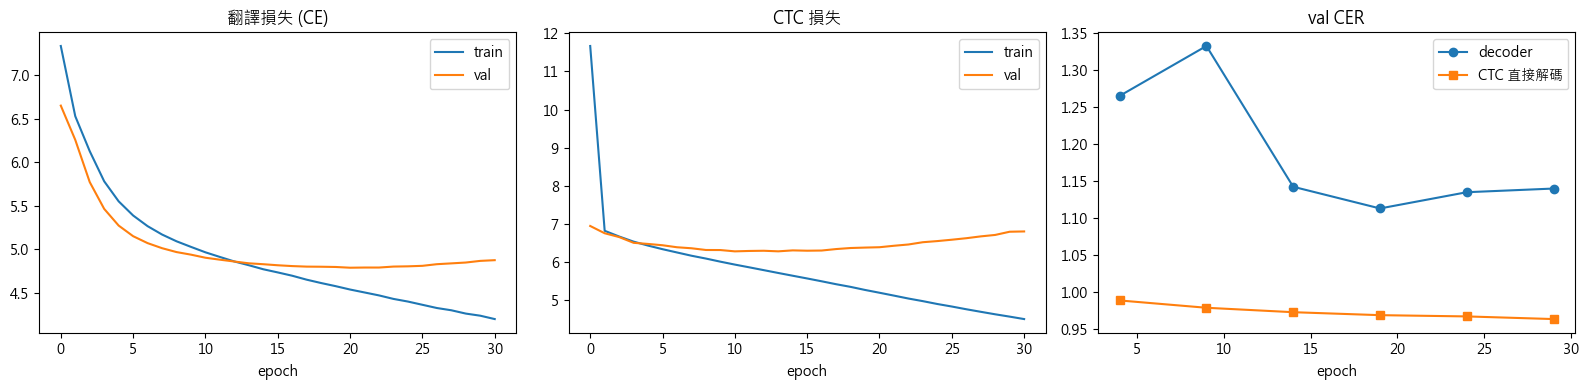

In [9]:
# 訓練曲線
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "DejaVu Sans"]   # 中文標題
plt.rcParams["axes.unicode_minus"] = False

h = np.array(history)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(h[:, 0], label="train")
axes[0].plot(h[:, 1], label="val")
axes[0].set_title("翻譯損失 (CE)")
axes[1].plot(h[:, 2], label="train")
axes[1].plot(h[:, 3], label="val")
axes[1].set_title("CTC 損失")
ok = ~np.isnan(h[:, 4])
axes[2].plot(np.where(ok)[0], h[ok, 4], "o-", label="decoder")
axes[2].plot(np.where(ok)[0], h[ok, 5], "s-", label="CTC 直接解碼")
axes[2].set_title("val CER")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## Predictions
同時輸出 decoder (翻譯) 與 CTC 直接解碼兩份預測。

In [10]:
PRED_SPLIT = "test"

vocab = load_vocab()
dataset = SignDataset(PRED_SPLIT, vocab)
loader = DataLoader(dataset, BATCH_SIZE, collate_fn=collate)

model = SignTransformerCTC(len(vocab)).to(DEVICE)
model.load_state_dict(torch.load(CKPT_DIR / "best.pt", map_location=DEVICE))
refs = [text for _, text in dataset.rows]

for pred_dir, decoder, label in ((PRED_DIR, greedy_decode, "decoder"), (PRED_DIR_CTC, ctc_greedy_decode, "CTC")):
    preds = predict_loader(model, loader, vocab, decoder)
    pred_dir.mkdir(parents=True, exist_ok=True)
    with (pred_dir / f"{PRED_SPLIT}_predictions.csv").open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f)
        writer.writerow(("path", "target", "prediction"))
        writer.writerows((path, ref, pred) for (path, _), ref, pred in zip(dataset.rows, refs, preds))
    print(f"{label}：{PRED_SPLIT} CER = {char_error_rate(preds, refs):.3f}")
    for (path, _), ref, pred in list(zip(dataset.rows, refs, preds))[:5]:
        print(f"  {path}\n    答案：{ref}\n    預測：{pred}")
    print()

load test: 100%|██████████| 2265/2265 [00:14<00:00, 158.92it/s]


decoder：test CER = 1.167
  2/10/000641_001738_s00.npy
    答案：台鐵445次台東往樹林的普悠瑪號
    預測：美國總統川普發表示
  2/10/000641_001738_s01.npy
    答案：昨天晚間9點多行經和平站附近時
    預測：中國時報是 昨天晚間發生火車輛
  2/10/000641_001738_s02.npy
    答案：撞到一顆巨大落石
    預測：在南部落幕
  2/10/000641_001738_s03.npy
    答案：導致1到3節車廂出軌
    預測：昨天下午開始進行
  2/10/000641_001738_s04.npy
    答案：所幸沒有翻覆 旅客都平安
    預測：不過因為不滿

CTC：test CER = 0.963
  2/10/000641_001738_s00.npy
    答案：台鐵445次台東往樹林的普悠瑪號
    預測：美國
  2/10/000641_001738_s01.npy
    答案：昨天晚間9點多行經和平站附近時
    預測：
  2/10/000641_001738_s02.npy
    答案：撞到一顆巨大落石
    預測：
  2/10/000641_001738_s03.npy
    答案：導致1到3節車廂出軌
    預測：
  2/10/000641_001738_s04.npy
    答案：所幸沒有翻覆 旅客都平安
    預測：而



## 評估
跟原本 notebook 的評估方式相同：基準線、套句 vs 新句、去除重複迴圈、字元精確率 / 召回率。

In [11]:
# 迴圈 = 同一個字連續 5 次以上，或同一段 2~4 字連續 3 次以上 (「5000」「999」「111年」不算)
LOOP_RE = re.compile(r"(.)\1{4,}|(.{2,4}?)\2{2,}")


def pad(text, width, left=True):
    """依顯示寬度補空白 (中文字佔 2 格)，讓表格對齊。"""
    w = sum(2 if unicodedata.east_asian_width(ch) in "WF" else 1 for ch in str(text))
    space = " " * max(0, width - w)
    return f"{text}{space}" if left else f"{space}{text}"


def table_row(label, values, label_width=24, width=12):
    cells = [pad("" if v is None else (f"{v:.3f}" if isinstance(v, float) else v), width, left=False) for v in values]
    return pad(label, label_width) + "".join(cells)


def clean_repeats(text):
    """「中國中國中國中國」→「中國」"""
    return LOOP_RE.sub(lambda m: m.group(1) or m.group(2), text)


def char_prf(preds, refs):
    """不看順序的字元精確率、召回率、F1。"""
    hit = n_pred = n_ref = 0
    for p, r in zip(preds, refs):
        hit += sum((Counter(p) & Counter(r)).values())
        n_pred, n_ref = n_pred + len(p), n_ref + len(r)
    prec, rec = hit / max(1, n_pred), hit / max(1, n_ref)
    return prec, rec, 2 * prec * rec / max(1e-9, prec + rec)


def shuffled(preds, groups=None, seed=SEED):
    """打亂預測跟答案的配對。groups 不是 None 時只在同一組 (同一則新聞) 裡打亂。"""
    rng = random.Random(seed)
    if groups is None:
        out = preds[:]
        rng.shuffle(out)
        return out
    out, by_group = preds[:], defaultdict(list)
    for i, g in enumerate(groups):
        by_group[g].append(i)
    for idx in by_group.values():
        perm = idx[:]
        rng.shuffle(perm)
        for a, b in zip(idx, perm):
            out[a] = preds[b]
    return out


def evaluate(pred_csv, train_csv, verbose=True):
    """回傳評估結果 dict；verbose=True 時印出表格。"""
    with Path(pred_csv).open(encoding="utf-8-sig", newline="") as f:
        rows = list(csv.DictReader(f))
    with Path(train_csv).open(encoding="utf-8-sig", newline="") as f:
        train_freq = Counter(row["text"] for row in csv.DictReader(f))

    paths = [r["path"] for r in rows]
    refs = [r["target"] for r in rows]
    raw = [r["prediction"] for r in rows]
    preds = [clean_repeats(p) for p in raw]
    clips = [p.rsplit("_s", 1)[0] for p in paths]
    seen = [train_freq[r] > 0 for r in refs]
    most_common = train_freq.most_common(1)[0][0]

    def sub(mask):
        idx = [i for i, m in enumerate(mask) if m]
        return [preds[i] for i in idx], [refs[i] for i in idx]

    new_p, new_r = sub([not s for s in seen])
    old_p, old_r = sub(seen)
    res = {
        "n": len(refs),
        "n_new": len(new_r),
        "loop_rate": sum(p != c for p, c in zip(raw, preds)) / len(raw),
        "unique_rate": len(set(raw)) / len(raw),
        "cer_raw": char_error_rate(raw, refs),
        "cer": char_error_rate(preds, refs),
        "cer_seen": char_error_rate(old_p, old_r) if old_r else float("nan"),
        "cer_new": char_error_rate(new_p, new_r) if new_r else float("nan"),
        "prf": char_prf(preds, refs),
        "prf_new": char_prf(new_p, new_r) if new_r else (float("nan"),) * 3,
        "base_empty": 1.0,
        "base_const": char_error_rate([most_common] * len(refs), refs),
        "base_shuffle": char_error_rate(shuffled(preds), refs),
        "base_shuffle_clip": char_error_rate(shuffled(preds, clips), refs),
        "prf_shuffle": char_prf(shuffled(preds), refs),
        "prf_shuffle_clip": char_prf(shuffled(preds, clips), refs),
    }
    if not verbose:
        return res

    print(f"{pred_csv}：{res['n']} 句，其中 {res['n_new']} 句 ({res['n_new'] / res['n']:.0%}) 沒在訓練集出現過")
    print(f"不同的預測：{res['unique_rate']:.0%}，有重複迴圈：{res['loop_rate']:.1%}\n")
    print(table_row("", ["CER", "字元精確率", "字元召回率"]))
    print(table_row("模型 (原始輸出)", [res["cer_raw"]]))
    print(table_row("模型 (去除重複迴圈)", [res["cer"], *res["prf"][:2]]))
    print(table_row("  └ 套句 (訓練集有)", [res["cer_seen"]]))
    print(table_row("  └ 新句 (訓練集沒有)", [res["cer_new"], *res["prf_new"][:2]]))
    print("-" * 60)
    print(table_row("基準：空字串", [res["base_empty"]]))
    print(table_row("基準：固定輸出最常見句", [res["base_const"]]))
    print(table_row("基準：全部打亂配對", [res["base_shuffle"], *res["prf_shuffle"][:2]]))
    print(table_row("基準：同則新聞內打亂", [res["base_shuffle_clip"], *res["prf_shuffle_clip"][:2]]))
    return res


for pred_dir in (PRED_DIR, PRED_DIR_CTC):
    evaluate(pred_dir / f"{PRED_SPLIT}_predictions.csv", DATA_DIR / "train.csv")
    print()

predictions_ctc\test_predictions.csv：2265 句，其中 2115 句 (93%) 沒在訓練集出現過
不同的預測：78%，有重複迴圈：11.9%

                                 CER  字元精確率  字元召回率
模型 (原始輸出)                1.167
模型 (去除重複迴圈)            0.971       0.156       0.126
  └ 套句 (訓練集有)            0.369
  └ 新句 (訓練集沒有)          0.999       0.122       0.097
------------------------------------------------------------
基準：空字串                   1.000
基準：固定輸出最常見句         0.988
基準：全部打亂配對             1.074       0.037       0.030
基準：同則新聞內打亂           1.052       0.067       0.054

predictions_ctc_enc\test_predictions.csv：2265 句，其中 2115 句 (93%) 沒在訓練集出現過
不同的預測：9%，有重複迴圈：0.0%

                                 CER  字元精確率  字元召回率
模型 (原始輸出)                0.963
模型 (去除重複迴圈)            0.963       0.569       0.039
  └ 套句 (訓練集有)            0.458
  └ 新句 (訓練集沒有)          0.987       0.345       0.014
------------------------------------------------------------
基準：空字串                   1.000
基準：固定輸出最常見句         0.988
基準：全部打亂配對             0.999       

## 跟之前的實驗比較
讀各實驗存好的預測 csv。還沒跑過的會自動略過。

**怎麼判斷**：「新句 CER」要明顯低於之前的約 1.03、「新句精確率」要明顯高於約 0.09；
如果 CTC 直接解碼的新句精確率也明顯高於「同則打亂基準」的精確率，代表 encoder 真的從手勢讀到了字。

In [12]:
EXPERIMENTS = {          # 名稱: (預測資料夾, 資料資料夾)
    "原本": ("predictions", "data"),
    "寬鬆 m0.5": ("predictions_m0.5", "data_m0.5"),
    f"{RUN_TAG[1:]} decoder": (PRED_DIR, DATA_DIR),
    f"{RUN_TAG[1:]} CTC": (PRED_DIR_CTC, DATA_DIR),
}

results, test_sets = {}, {}
for name, (pred_dir, data_dir) in EXPERIMENTS.items():
    pred_csv = Path(pred_dir) / f"{PRED_SPLIT}_predictions.csv"
    if not pred_csv.exists():
        print(f"略過 {name}：找不到 {pred_csv}")
        continue
    results[name] = evaluate(pred_csv, Path(data_dir) / "train.csv", verbose=False)
    with pred_csv.open(encoding="utf-8-sig", newline="") as f:
        test_sets[name] = {row["path"] for row in csv.DictReader(f)}

if len(set(map(frozenset, test_sets.values()))) > 1:
    print("[注意] 各實驗的測試集句子不完全一樣，比較結果僅供參考")

cols = [
    ("CER", "cer"), ("新句 CER", "cer_new"), ("套句 CER", "cer_seen"),
    ("新句精確率", lambda r: r["prf_new"][0]), ("新句召回率", lambda r: r["prf_new"][1]),
    ("迴圈率", "loop_rate"), ("固定句基準", "base_const"), ("同則打亂精確率", lambda r: r["prf_shuffle_clip"][0]),
]
print()
print(table_row("實驗", [c for c, _ in cols], label_width=16, width=15))
for name, r in results.items():
    print(table_row(name, [(key(r) if callable(key) else r[key]) for _, key in cols], label_width=16, width=15))


實驗                        CER       新句 CER       套句 CER     新句精確率     新句召回率         迴圈率     固定句基準 同則打亂精確率
原本                      1.005          1.033          0.413          0.088          0.075          0.062          0.988          0.061
寬鬆 m0.5                 0.997          1.024          0.411          0.092          0.077          0.060          0.988          0.066
ctc decoder               0.971          0.999          0.369          0.122          0.097          0.119          0.988          0.067
ctc CTC                   0.963          0.987          0.458          0.345          0.014          0.000          0.988          0.146
